# Supplementary figures S1, S2, S3, S6, S7, S10, S11, S12

Supplementary figures S1, S2, S3, S6, S7, S10, S11, S12 (data-light ones).
S4/S5 -> make_figS04_S05_diurnal.py ; S8/S9 -> make_figS08_S09.py.

Per-year R² (S7) and the mean of years are supplementary; the headline R² in the paper is the pooled out-of-fold R² (notebook A2).

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()          # notebooks/ folder
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from fig_common import draw_termmap
from termmap_utils import DATA, load_front
from style import *   # PM25, O3, NAVY, GREY, RED, LIGHT, ROOT, DATA_OUT, save_fig, panel_label

In [2]:
# Settings (edit here, then Run All)
# Figsize shrunk (was 10.5-11.5in wide, well past every other figure's ~8-9.6in) and fonts bumped
# throughout 2026-09-24 (user: text reads small once scaled to the page's textwidth).
FIGSIZE = dict(S01=(9.2, 4.2), S02=(9.5, 4.3), S03=(9.0, 7.6), S06=(7.2, 4.8), S07=(9.2, 4.4),
               S10=(6.4, 4.6), S11=(9.0, 4.4), S12=(9.5, 7.8))      # inches
MARKER, MS = "o", 3.5                    # line markers (S2, S3)
DIAMOND_MS = 5.5                         # persistence marker in S7
SECTOR_CMAP = "Blues"                    # S1b sector colours (was YlOrBr; blue instead of orange, 2026-09-23)
MAX_COMPLEXITY = 25                      # term-map x range (S12)
PM25 = PM25_BLUE                         # blue instead of orange in every SI figure (2026-09-23, user request)

In [3]:
# Analysis
B, M = DATA / "bogota", DATA / "medellin"
def rd(p):
    d = pd.read_parquet(p); d["date"] = pd.to_datetime(d["date"]); return d

saved /path/to/project/Paper/figures/figS01_fire_hotspots.png


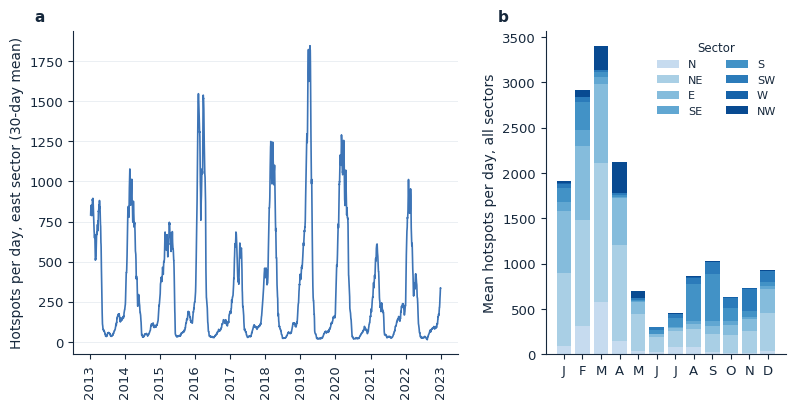

In [4]:
# S1: fire hotspots
h = rd(B / "bogota_hotspots_daily.parquet"); h = h[h.date <= "2022-12-31"]   # the study period (the corrected product runs to 2026)
sec = [c for c in h.columns if c.startswith("hotspots_sector_") and not c.endswith("transport")]
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE['S01'], gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.28))
ax = axes[0]
e = h.set_index("date")["hotspots_sector_E"]
ax.plot(e.index, e.rolling(30, min_periods=10).mean(), color=PM25, lw=1.2)
ax.set_ylabel("hotspots per day, east sector (30-day mean)", fontsize=10); ax.set_xlabel("")
ax.tick_params(labelsize=9.5)
plt.setp(ax.get_xticklabels(), rotation=90)   # 2026-11-02: years rotated 90 degrees
ax.grid(axis="y", color=LIGHT, lw=0.6); ax.text(-0.1, 1.03, "(a)", transform=ax.transAxes, fontsize=11, fontweight="bold")
ax = axes[1]
mon = h.assign(m=h.date.dt.month).groupby("m")[sec].mean()
bot = np.zeros(12)
cm = plt.get_cmap(SECTOR_CMAP)(np.linspace(0.25, 0.9, len(sec)))
for c, col in zip(sec, cm):
    ax.bar(mon.index, mon[c], bottom=bot, color=col, label=c.replace("hotspots_sector_", ""), width=0.8); bot += mon[c].to_numpy()
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND")); ax.set_ylabel("mean hotspots per day, all sectors", fontsize=10)
ax.tick_params(labelsize=9.5)
ax.legend(frameon=False, fontsize=8, ncol=2, title="sector", title_fontsize=8.5); ax.text(-0.2, 1.03, "(b)", transform=ax.transAxes, fontsize=11, fontweight="bold")
save_fig(fig, "figS01_fire_hotspots")

saved /path/to/project/Paper/figures/figS02_monthly_climatologies.png


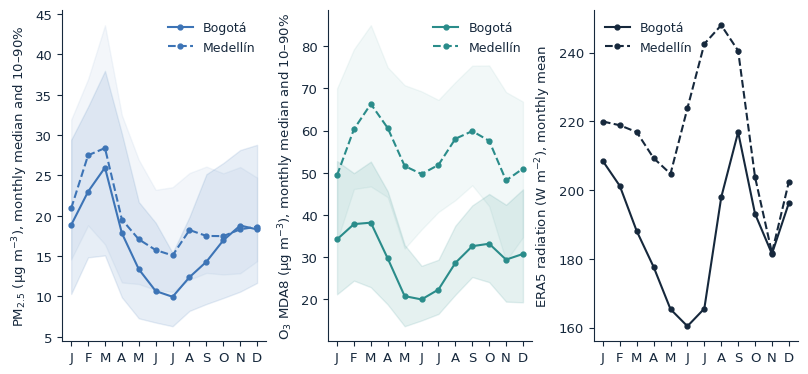

In [5]:
# S2: climatologies
# E2 (2026-09-22): Bogotá O3 is ppb and Medellín O3 is µg m-3 (notebook A4) -- plotting them raw on one
# axis made Medellín look ~2.5x higher partly from the unit mismatch. Bogotá is converted to µg m-3 at
# its local mean conditions (751 hPa, 14.9 C) so both cities share one correctly labelled axis.
BOGOTA_O3_PPB_TO_UGM3 = 1.51   # = 48.00 * 751 hPa * 100 / (8.314 * 288.05 K) / 1000, same factor as notebook A4
fig, axes = plt.subplots(1, 3, figsize=FIGSIZE['S02'], gridspec_kw=dict(wspace=0.3))
o3_bog = rd(B / "bogota_o3_master_dataset.parquet"); o3_bog["o3"] = o3_bog["o3"] * BOGOTA_O3_PPB_TO_UGM3
srcs = [("PM$_{2.5}$ (µg m$^{-3}$)", "pm25", PM25, [("Bogotá", rd(B / "bogota_master_dataset.parquet"), "-"), ("Medellín", rd(M / "medellin_master_dataset.parquet"), "--")]),
        ("O$_3$ MDA8 (µg m$^{-3}$)", "o3", O3, [("Bogotá", o3_bog, "-"), ("Medellín", rd(M / "medellin_o3_master_dataset.parquet"), "--")])]
for ax, (lab, col, c, series) in zip(axes[:2], srcs):
    for name, d, ls in series:
        g = d.assign(m=d.date.dt.month).groupby("m")[col]
        ax.plot(range(1, 13), g.median(), ls, color=c, marker=MARKER, ms=MS, label=name)
        ax.fill_between(range(1, 13), g.quantile(0.1), g.quantile(0.9), color=c, alpha=0.12 if ls == "-" else 0.06)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND")); ax.set_ylabel(lab + ", monthly median and 10–90%", fontsize=9.5); ax.legend(frameon=False, fontsize=9)
    ax.tick_params(labelsize=9.5)
e1 = rd(B / "bogota_master_dataset.parquet"); ax = axes[2]
for name, d, ls in [("Bogotá", e1, "-"), ("Medellín", rd(M / "medellin_master_dataset.parquet"), "--")]:
    ax.plot(range(1, 13), d.assign(m=d.date.dt.month).groupby("m")["radiation_mean"].mean(), ls, color=NAVY, marker=MARKER, ms=MS, label=name)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND")); ax.set_ylabel("ERA5 radiation (W m$^{-2}$), monthly mean", fontsize=9.5); ax.legend(frameon=False, fontsize=9)
ax.tick_params(labelsize=9.5)
save_fig(fig, "figS02_monthly_climatologies")

saved /path/to/project/Paper/figures/figS03_sfs_trajectories.png


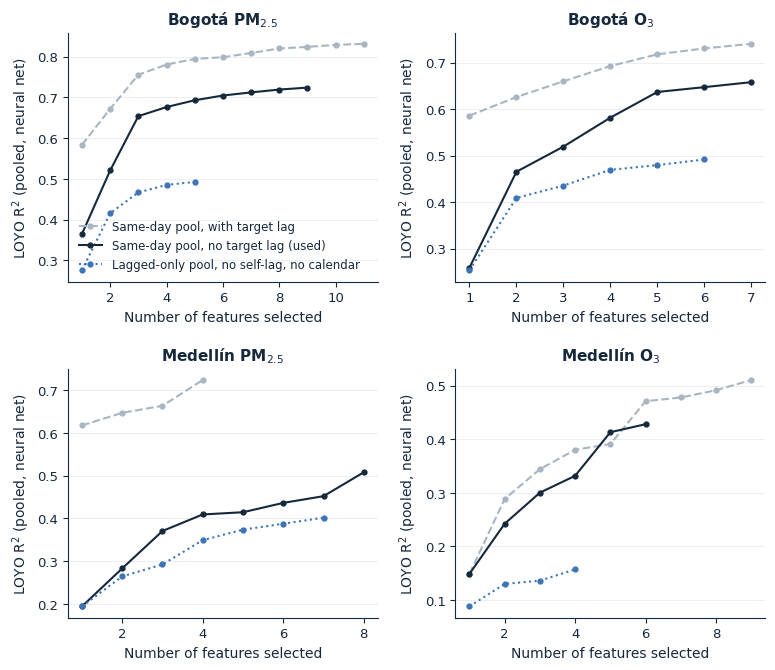

In [6]:
# S3: SFS trajectories
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE['S03'], sharey=False, gridspec_kw=dict(hspace=0.35, wspace=0.25))
cfg = [("Bogotá PM$_{2.5}$", B/"bogota_feature_selection.json", B/"bogota_forecast_feature_selection.json"),
       ("Bogotá O$_3$", B/"bogota_o3_feature_selection.json", B/"bogota_o3_forecast_feature_selection.json"),
       ("Medellín PM$_{2.5}$", M/"medellin_feature_selection.json", M/"medellin_forecast_feature_selection.json"),
       ("Medellín O$_3$", M/"medellin_o3_feature_selection.json", M/"medellin_o3_forecast_feature_selection.json")]
for ax, (ttl, ep, fp) in zip(axes.ravel(), cfg):
    e = json.load(open(ep)); f = json.load(open(fp))
    for lab, sc, st in [("same-day pool, with target lag", e.get("scores_with_lag"), "--"), ("same-day pool, no target lag (used)", e.get("scores_no_lag"), "-"),
                        ("lagged-only pool, no self-lag, no calendar", f["no_self_lag_no_calendar"]["scores"], ":")]:
        if sc: ax.plot(range(1, len(sc) + 1), sc, st, marker=MARKER, ms=MS, lw=1.5, color=NAVY if st == "-" else (GREY if st == "--" else PM25), label=lab)
    ax.set_title(ttl, fontsize=11); ax.set_xlabel("number of features selected", fontsize=10); ax.set_ylabel("LOYO R$^2$ (pooled, neural net)", fontsize=10); ax.grid(axis="y", color=LIGHT, lw=0.6)
    ax.tick_params(labelsize=9.5)
axes[0, 0].legend(frameon=False, fontsize=8.5)
save_fig(fig, "figS03_sfs_trajectories")

saved /path/to/project/Paper/figures/figS06_nox_voc_sensitivity.png
 pm25_percentile   pm25  dO3_dNO  dO3_dPM25  ratio_abs       larger
               5  7.951   -0.188      0.469      2.499 |dO3/dPM2.5|
              10  9.045   -0.194      0.426      2.197 |dO3/dPM2.5|
              25 11.941   -0.209      0.348      1.664 |dO3/dPM2.5|
              50 17.048   -0.230      0.268      1.165 |dO3/dPM2.5|
              75 23.249   -0.249      0.213      0.855    |dO3/dNO|
              90 30.134   -0.266      0.176      0.659    |dO3/dNO|
              95 33.661   -0.274      0.162      0.590    |dO3/dNO|
              99 41.347   -0.289      0.139      0.481    |dO3/dNO|
crossover PM2.5 = 19.84 at percentile 63.0


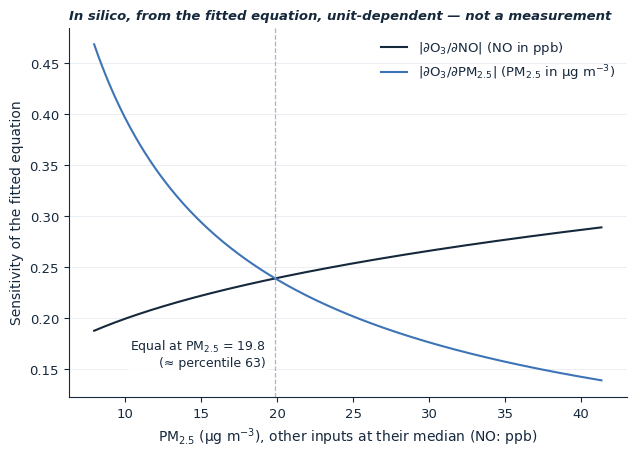

In [7]:
# S6: NOx/VOC sensitivity
o = rd(B / "bogota_o3_master_dataset.parquet")
o["fire_eq1"] = o["hotspots_sector_E_lag2"] + o["hotspots_sector_N"]   # 2026-10-20: fire term of PM2.5 Eq. 1 (after the fire-file correction)
# 2026-10-20: the lead O3 equation (notebook A2) is O3 = sqrt( a SW sqrt(PM2.5 NO2 / NO) + b F_E,-2 ), a, b refitted on the same days.
# Derivatives are numerical, from the fitted function itself, with the other inputs at their median.
from scipy.optimize import curve_fit
feats = ["no", "no2", "radiation_mean", "pm25", "hotspots_sector_E_lag2"]
d = o.dropna(subset=feats + ["no2", "no", "radiation_mean", "hotspots_sector_E_lag2", "rh_2m", "wind_speed_era5", "w700", "temp_2m", "pm25", "o3"])     # the same days as A2
def o3_lead(X, a, b):
    no, no2, sw, pm25, fe2 = X
    return np.sqrt(np.clip(a * sw * np.sqrt(np.clip(pm25 * no2 / no, 0, None)) + b * fe2, 0, None))
(a_, b_), _ = curve_fit(o3_lead, tuple(d[c].to_numpy(float) for c in feats), d.o3.to_numpy(float), p0=[0.4916, 0.1079])
med = d[feats].median()
def f(no, pm25): return o3_lead((no, med.no2, med.radiation_mean, pm25, med.hotspots_sector_E_lag2), a_, b_)
def dno(x): return (f(med.no + 1e-3, x) - f(med.no - 1e-3, x)) / 2e-3
def dpm(x): return (f(med.no, x + 1e-3) - f(med.no, x - 1e-3)) / 2e-3
pcts = [5, 10, 25, 50, 75, 90, 95, 99]; pm = np.percentile(d.pm25, pcts)
rows = []
for p, x in zip(pcts, pm):
    dn, dp = dno(x), dpm(x)
    rows.append(dict(pm25_percentile=p, pm25=x, dO3_dNO=dn, dO3_dPM25=dp, ratio_abs=abs(dp / dn), larger="|dO3/dPM2.5|" if abs(dp) > abs(dn) else "|dO3/dNO|"))
s6 = pd.DataFrame(rows); s6.to_csv(DATA_OUT / "nox_voc_sensitivity_lead_equation.csv", index=False)
xs = np.linspace(pm.min(), pm.max(), 400)
dn = np.array([dno(x) for x in xs]); dp = np.array([dpm(x) for x in xs])
# The crossing point of the two sensitivities depends on the units of NO (ppb) and PM2.5 (ug m-3) and is not a regime threshold.
sgn = np.sign(np.abs(dp) - np.abs(dn)); k = np.where(np.diff(sgn) != 0)[0]
cross = float(xs[k[0]]) if len(k) else np.nan
fig, ax = plt.subplots(figsize=FIGSIZE['S06'])
ax.plot(xs, np.abs(dn), color=NAVY, label="|∂O$_3$/∂NO| (NO in ppb)"); ax.plot(xs, np.abs(dp), color=PM25, label="|∂O$_3$/∂PM$_{2.5}$| (PM$_{2.5}$ in µg m$^{-3}$)")
if np.isfinite(cross):
    ax.axvline(cross, color=GREY, ls="--", lw=0.9)
    # y in axes fraction (the y axis no longer starts at 0); one short line in the empty band above both curves
    ax.text(cross - 0.6, 0.12, f"equal at PM$_{{2.5}}$ = {cross:.1f}\n(≈ percentile {(d.pm25 < cross).mean()*100:.0f})",
            transform=ax.get_xaxis_transform(), fontsize=9, va="center", ha="right",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2))
ax.set_xlabel("PM$_{2.5}$ (µg m$^{-3}$), other inputs at their median (NO: ppb)", fontsize=10); ax.set_ylabel("sensitivity of the fitted equation", fontsize=10)
ax.tick_params(labelsize=9.5)
ax.legend(frameon=False, fontsize=9.5, loc="upper right"); ax.grid(axis="y", color=LIGHT, lw=0.6)
ax.set_title("In silico, from the fitted equation, unit-dependent — not a measurement", fontsize=9.5, style="italic", loc="left")
save_fig(fig, "figS06_nox_voc_sensitivity")
print(s6.round(3).to_string(index=False)); print("crossover PM2.5 =", round(float(cross), 2), "at percentile", round(float((d.pm25 < cross).mean() * 100), 1))

saved /path/to/project/Paper/figures/figS07_loyo_by_year.png


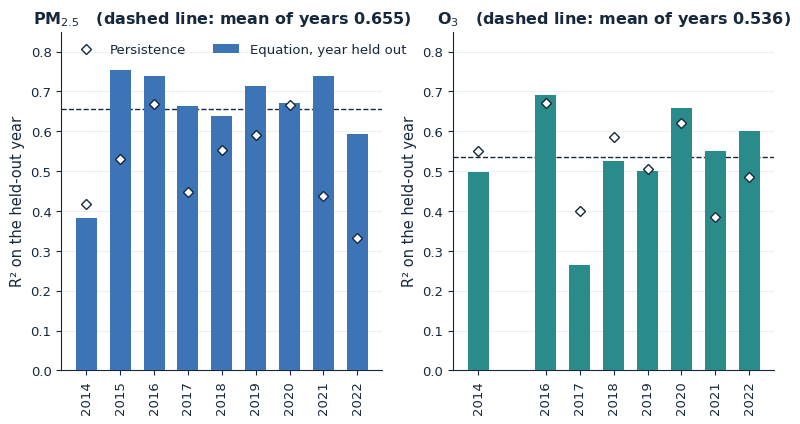

In [8]:
# S7: per-year LOYO
by = pd.read_csv(DATA_OUT / "loyo_by_year.csv"); pp = pd.read_csv(DATA_OUT / "equation_vs_persistence_by_year.csv")
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE['S07'], gridspec_kw=dict(wspace=0.22))
for ax, (pol, col, ttl) in zip(axes, [("pm25", PM25, "PM$_{2.5}$"), ("o3", O3, "O$_3$")]):
    s = by[by.pollutant == pol]; q = pp[pp.pollutant == pol]
    ax.bar(s.year, s.r2, color=col, width=0.62, label="equation, year held out", zorder=3)
    ax.plot(q.year, q.persistence_r2, "D", color=NAVY, mfc="white", ms=DIAMOND_MS, label="persistence", zorder=4)
    ax.axhline(s.r2.mean(), color=NAVY, lw=1, ls="--"); pass
    ax.set_title(f"{ttl}   (dashed line: mean of years {s.r2.mean():.3f})", fontsize=11.5); ax.set_ylabel("R² on the held-out year", fontsize=10.5); ax.set_ylim(0, 0.85); ax.grid(axis="y", color=LIGHT, lw=0.6, zorder=0)
    ax.set_xticks(s.year); ax.set_xticklabels(s.year, rotation=90); ax.tick_params(axis="x", labelsize=9.5); ax.tick_params(axis="y", labelsize=9.5)
axes[0].legend(frameon=False, fontsize=9.5, loc="upper left", ncol=2)
save_fig(fig, "figS07_loyo_by_year")

saved /path/to/project/Paper/figures/figS10_tropomi_no2_check.png
S10 {'none': 0.669, 'ground NO2': 0.604, 'TROPOMI NO2': 0.653, 'both': 0.597} n 724


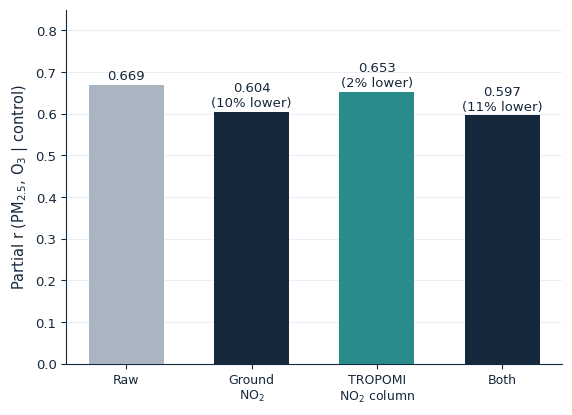

In [9]:
# S10: TROPOMI NO2 check
def partial(data, x, y, ctrl):
    A = np.column_stack([np.ones(len(data))] + [data[c].to_numpy(float) for c in ctrl]) if ctrl else np.ones((len(data), 1))
    rx = data[x].to_numpy(float) - A @ np.linalg.lstsq(A, data[x].to_numpy(float), rcond=None)[0]
    ry = data[y].to_numpy(float) - A @ np.linalg.lstsq(A, data[y].to_numpy(float), rcond=None)[0]
    return float(np.corrcoef(rx, ry)[0, 1])
tr = pd.read_csv(ROOT / "Data/external/tropomi_hcho/bogota_no2_daily.csv", parse_dates=["date"]).rename(columns={"no2_trop_col_mol_m2": "no2_tropomi"})
req = ["pm25", "o3", "no2", "no", "co", "temp_2m", "rh_2m", "blh_mean", "radiation_mean", "fire_eq1"]
canon = o.dropna(subset=req); can_t = canon.merge(tr[["date", "no2_tropomi"]], on="date").dropna(subset=["no2_tropomi"])
res = {"none": partial(can_t, "pm25", "o3", []), "ground NO2": partial(can_t, "pm25", "o3", ["no2"]),
       "TROPOMI NO2": partial(can_t, "pm25", "o3", ["no2_tropomi"]), "both": partial(can_t, "pm25", "o3", ["no2", "no2_tropomi"])}
pd.DataFrame([dict(control=k, partial_r=v, pct_attenuation=100 * (res["none"] - v) / res["none"], n=len(can_t)) for k, v in res.items()]).to_csv(DATA_OUT / "tropomi_no2_check_canonical.csv", index=False)
fig, ax = plt.subplots(figsize=FIGSIZE['S10'])
vals = list(res.values()); labs = ["raw", "ground\nNO$_2$", "TROPOMI\nNO$_2$ column", "both"]
ax.bar(range(4), vals, color=[GREY, NAVY, O3, NAVY], width=0.6, zorder=3)
for i, v in enumerate(vals): ax.text(i, v + 0.012, f"{v:.3f}" + ("" if i == 0 else f"\n({100*(res['none']-v)/res['none']:.0f}% lower)"), ha="center", fontsize=9.5)
ax.set_xticks(range(4)); ax.set_xticklabels(labs, fontsize=9); ax.set_ylim(0, 0.85); ax.set_ylabel("partial r (PM$_{2.5}$, O$_3$ | control)", fontsize=10.5)
ax.tick_params(axis="y", labelsize=9.5)
# 2026-09-28 (user: check the SI figures for the same title-in-plot issue as Figs S8/S13): removed the
# on-plot title -- it only restated the "724 days" / "valid TROPOMI retrieval" wording the caption already
# gives in full.
ax.grid(axis="y", color=LIGHT, lw=0.6, zorder=0)
save_fig(fig, "figS10_tropomi_no2_check")
print("S10", {k: round(v, 3) for k, v in res.items()}, "n", len(can_t))

saved /path/to/project/Paper/figures/figS11_pm25_ablation.png


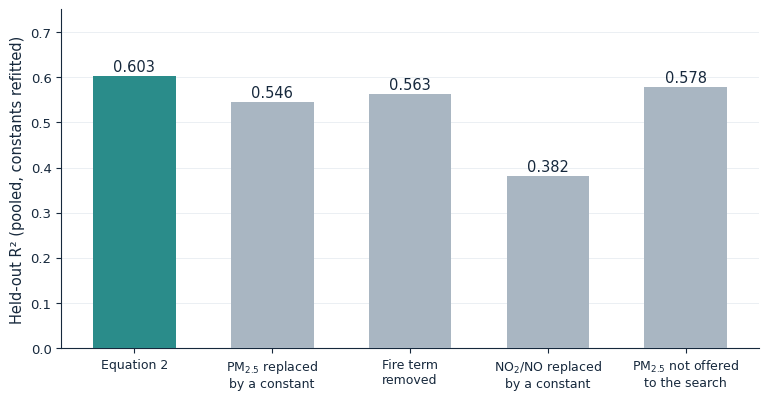

In [10]:
# S11: ablation bar
# 2026-10-20: the ozone feature-selection ablation (PM2.5 and every PM2.5-derived feature removed from the pool; 0.646 against 0.602) was run
# before the fire-file correction and is not repeated: the corrected selection no longer picks PM2.5 at all. The equivalent test now is at the
# level of the equation (notebook A5): each piece of the ozone lead equation replaced by a free constant or removed, constants refitted, same days.
abl = pd.read_csv(DATA_OUT / "o3_lead_ablations.csv"); t2 = pd.read_csv(DATA_OUT / "tableS2_constrained_vs_freeform.csv")
nopm = float(t2[t2.form.str.contains("PM2.5 not offered")].r2_pooled.iloc[0])
labs = ["Eq. 2", "PM$_{2.5}$ replaced\nby a constant", "fire term\nremoved", "NO$_2$/NO replaced\nby a constant", "PM$_{2.5}$ not offered\nto the search"]
vals = [float(abl.r2_pooled.iloc[0]), float(abl.r2_pooled.iloc[1]), float(abl.r2_pooled.iloc[2]), float(abl.r2_pooled.iloc[3]), nopm]
fig, ax = plt.subplots(figsize=FIGSIZE['S11'])
ax.bar(range(5), vals, color=[O3, GREY, GREY, GREY, GREY], width=0.6, zorder=3)
for i, v in enumerate(vals): ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=10.5)
ax.set_xticks(range(5)); ax.set_xticklabels(labs, fontsize=9)
ax.set_ylim(0, 0.75); ax.tick_params(axis="y", labelsize=9.5)
ax.set_ylabel("held-out R² (pooled, constants refitted)", fontsize=10.5); ax.grid(axis="y", color=LIGHT, lw=0.6, zorder=0)
save_fig(fig, "figS11_pm25_ablation")

saved /path/to/project/Paper/figures/figS12_lagged_vs_explanatory.png


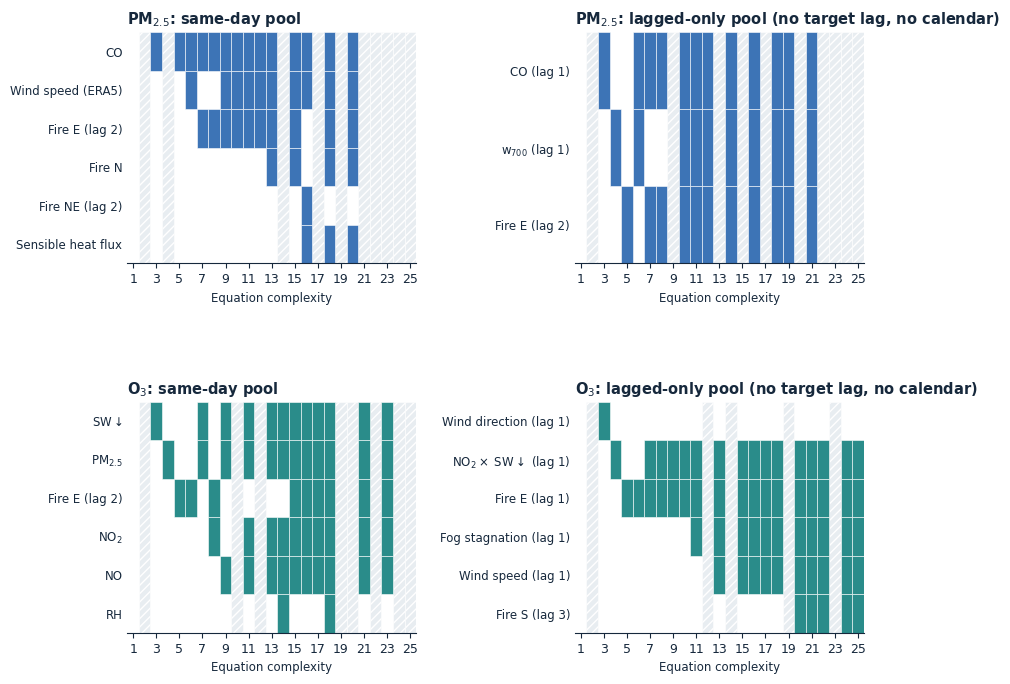

In [11]:
# S12: lagged vs explanatory term maps
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE['S12'], gridspec_kw=dict(hspace=0.6, wspace=0.55))
for (ax_l, ax_r), (lab, expl, lag, col) in zip(axes, [("PM$_{2.5}$", B/"bogota_pm25_pysr_units_pareto_front.csv", B/"bogota_pm25_forecast_interpretable_pysr_pareto.csv", PM25),
                                                     # 2026-10-06: same-day O3 = the front of the lead equation (constrained, T in pool), as for PM2.5
                                                     ("O$_3$", B/"bogota_o3_pysr_units_fire2_pm_pareto_front_seed0.csv", B/"bogota_o3_forecast_interpretable_pysr_pareto.csv", O3)]):
    draw_termmap(ax_l, load_front(expl), col, max_c=MAX_COMPLEXITY, label_size=8.5, tick_size=9); ax_l.set_title(f"{lab}: same-day pool", fontsize=10.5, loc="left")
    draw_termmap(ax_r, load_front(lag), col, max_c=MAX_COMPLEXITY, label_size=8.5, tick_size=9); ax_r.set_title(f"{lab}: lagged-only pool (no target lag, no calendar)", fontsize=10.5, loc="left")
save_fig(fig, "figS12_lagged_vs_explanatory")